In [11]:
import numpy as np
import matplotlib.pyplot as plt

#### Вспомогательные функции

In [12]:
def tridiag_solve(lower, main, upper, rhs):
    n = len(main)
    
    a = np.array(lower, dtype=float)   # нижняя диагональ (длина n, a[0] фиктивный)
    b = np.array(main, dtype=float)    # главная диагональ (длина n)
    c = np.array(upper, dtype=float)   # верхняя диагональ (длина n - 1)
    d = np.array(rhs, dtype=float)     # правая часть (длина n)
    
    P = np.zeros(n - 1, dtype=float) 
    Q = np.zeros(n - 1, dtype=float)  
    
    # Прямой ход
    P[0] = -c[0] / b[0]
    Q[0] = d[0] / b[0]
    
    for i in range(1, n - 1):
        denom = b[i] + a[i] * P[i - 1]
        P[i] = -c[i] / denom
        Q[i] = (d[i] - a[i] * Q[i - 1]) / denom
    
    # Обратный ход
    x = np.zeros(n, dtype=float)
    x[n - 1] = (d[n - 1] - a[n - 1] * Q[n - 2]) / (b[n - 1] + a[n - 1] * P[n - 2])
    
    for i in range(n - 2, -1, -1):
        x[i] = P[i] * x[i + 1] + Q[i]
    
    return x

# **4.1. Методы Эйлера, Рунге-Кутты и Адамса 4-го порядка**

In [9]:
def odu_system(x, u):
    y, z = u[0], u[1]
    sqrt_x = np.sqrt(x)

    dy_dx = z
    dz_dx = (z / sqrt_x) - ((x + sqrt_x - 8.0) / (4.0 * x**2)) * y
    return np.array([dy_dx, dz_dx], dtype=float)


def exact_solution(x):
    return (x**2 + 1.0 / x) * np.exp(np.sqrt(x))


def euler_method(f, x0, x_end, u0, h):
    n_steps = int(round((x_end - x0) / h))
    x = np.linspace(x0, x_end, n_steps + 1)
    u = np.zeros((n_steps + 1, len(u0)), dtype=float)
    u[0] = u0

    for n in range(n_steps):
        u[n + 1] = u[n] + h * f(x[n], u[n])

    return x, u


def rk_step(f, xn, un, h):
    k1 = f(xn, un)
    k2 = f(xn + 0.5 * h, un + 0.5 * h * k1)
    k3 = f(xn + 0.5 * h, un + 0.5 * h * k2)
    k4 = f(xn + h, un + h * k3)
    return un + (h / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)


def runge_kutta(f, x0, x_end, u0, h):
    n_steps = int(round((x_end - x0) / h))
    x = np.linspace(x0, x_end, n_steps + 1)
    u = np.zeros((n_steps + 1, len(u0)), dtype=float)
    u[0] = u0

    for n in range(n_steps):
        u[n + 1] = rk_step(f, x[n], u[n], h)

    return x, u


def adams(f, x0, x_end, u0, h):
    n_steps = int(round((x_end - x0) / h))

    x = np.linspace(x0, x_end, n_steps + 1)
    u = np.zeros((n_steps + 1, len(u0)), dtype=float)
    F = np.zeros((n_steps + 1, len(u0)), dtype=float)

    u[0] = u0
    F[0] = f(x[0], u[0])

    for n in range(3):
        u[n + 1] = rk_step(f, x[n], u[n], h)
        F[n + 1] = f(x[n + 1], u[n + 1])

    for n in range(3, n_steps):
        u[n + 1] = u[n] + (h / 24.0) * (
            55.0 * F[n] - 59.0 * F[n - 1] + 37.0 * F[n - 2] - 9.0 * F[n - 3]
        )
        F[n + 1] = f(x[n + 1], u[n + 1])

    return x, u


def runge_romberg_error(y_h, y_h2, p):
    return np.abs(y_h2[::2] - y_h) / (2.0**p - 1.0)


def solve_koshi_task(f, exact_func, x0, x_end, u0, h):
    x_h, u_euler_h = euler_method(f, x0, x_end, u0, h)
    _, u_rk4_h = runge_kutta(f, x0, x_end, u0, h)
    _, u_adams_h = adams(f, x0, x_end, u0, h)

    h_half = h / 2.0
    _, u_euler_h2 = euler_method(f, x0, x_end, u0, h_half)
    _, u_rk4_h2 = runge_kutta(f, x0, x_end, u0, h_half)
    _, u_adams_h2 = adams(f, x0, x_end, u0, h_half)

    y_exact = exact_func(x_h)
    y_euler = u_euler_h[:, 0]
    y_rk4 = u_rk4_h[:, 0]
    y_adams = u_adams_h[:, 0]

    err_rr_euler = runge_romberg_error(y_euler, u_euler_h2[:, 0], p=1)
    err_rr_rk4 = runge_romberg_error(y_rk4, u_rk4_h2[:, 0], p=4)
    err_rr_adams = runge_romberg_error(y_adams, u_adams_h2[:, 0], p=4)

    abs_err_euler = np.abs(y_exact - y_euler)
    abs_err_rk4 = np.abs(y_exact - y_rk4)
    abs_err_adams = np.abs(y_exact - y_adams)

    print("=" * 106)
    print(
        f"РЕШЕНИЕ ЗАДАЧИ КОШИ ДЛЯ ОДУ 2-ГО ПОРЯДКА НА ОТРЕЗКЕ [{x0}; {x_end}] С ШАГОМ h = {h}"
    )
    print("=" * 106)
    header = (
        f"{'n':^3} | {'x_n':^6} | {'Точное y(x)':^14} | "
        f"{'Эйлер':^14} | {'Рунге–Кутта':^14} | {'Адамс':^14}"
    )
    print(header)
    print("-" * len(header))

    for i in range(len(x_h)):
        print(
            f"{i:^3} | {x_h[i]:^6.2f} | {y_exact[i]:^14.8f} | "
            f"{y_euler[i]:^14.8f} | {y_rk4[i]:^14.8f} | {y_adams[i]:^14.8f}"
        )

    print("\n" + "=" * 116)
    print("ОЦЕНКА ПОГРЕШНОСТЕЙ В УЗЛАХ СЕТКИ:")
    print(
        "  * Абс. погр. (h)  — |y_точн(x_n) - y_числ(x_n)| на шаге h\n"
        "  * Рунге–Ромберг   — оценка погрешности решения на шаге h/2: |y_{h/2} - y_h| / (2^p - 1)"
    )
    print("=" * 116)
    err_header = (
        f"{'x_n':^6} | {'Эйлер абс.(h)':^14} | {'Эйлер РР(h/2)':^14} | "
        f"{'РК4 абс.(h)':^14} | {'РК4 РР(h/2)':^14} | {'Адамс абс.(h)':^14} | {'Адамс РР(h/2)':^14}"
    )
    print(err_header)
    print("-" * len(err_header))

    for i in range(len(x_h)):
        print(
            f"{x_h[i]:^6.2f} | {abs_err_euler[i]:^14.3e} | {err_rr_euler[i]:^14.3e} | "
            f"{abs_err_rk4[i]:^14.3e} | {err_rr_rk4[i]:^14.3e} | {abs_err_adams[i]:^14.3e} | {err_rr_adams[i]:^14.3e}"
        )

    print("\n" + "=" * 116)
    print("МАКСИМАЛЬНЫЕ ПОГРЕШНОСТИ НА ВСЁМ ОТРЕЗКЕ [1; 2]:")
    print(
        f"  1. Метод Эйлера (p=1):        max|y_точн - y_h| = {np.max(abs_err_euler):.3e}  |  max Рунге–Ромберг (h/2) = {np.max(err_rr_euler):.3e}"
    )
    print(
        f"  2. Метод Рунге–Кутты (p=4): max|y_точн - y_h| = {np.max(abs_err_rk4):.3e}  |  max Рунге–Ромберг (h/2) = {np.max(err_rr_rk4):.3e}"
    )
    print(
        f"  3. Метод Адамса (p=4):      max|y_точн - y_h| = {np.max(abs_err_adams):.3e}  |  max Рунге–Ромберг (h/2) = {np.max(err_rr_adams):.3e}"
    )
    print("=" * 116)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

    x_dense = np.linspace(x0, x_end, 200)
    ax1.plot(
        x_dense,
        exact_func(x_dense),
        "k-",
        linewidth=2.2,
        label="Точное решение $y(x)$",
    )
    ax1.plot(x_h, y_euler, "o--", color="crimson", label="Метод Эйлера (p=1)")
    ax1.plot(
        x_h,
        y_rk4,
        "s-.",
        color="royalblue",
        markersize=6,
        label="Метод Рунге–Кутты",
    )
    ax1.plot(
        x_h,
        y_adams,
        "^:",
        color="forestgreen",
        markersize=7,
        label="Метод Адамса",
    )
    ax1.set_title("Численное и точное решения задачи Коши", fontsize=12)
    ax1.set_xlabel("x", fontsize=11)
    ax1.set_ylabel("y(x)", fontsize=11)
    ax1.grid(True, linestyle=":", alpha=0.6)
    ax1.legend(loc="best")

    ax2.semilogy(
        x_h[1:],
        abs_err_euler[1:],
        "o--",
        color="crimson",
        label="Ошибка Эйлера",
    )
    ax2.semilogy(
        x_h[1:],
        abs_err_rk4[1:],
        "s-.",
        color="royalblue",
        label="Ошибка Рунге–Кутты",
    )
    ax2.semilogy(
        x_h[1:],
        abs_err_adams[1:],
        "^:",
        color="forestgreen",
        label="Ошибка Адамса",
    )
    ax2.set_title(
        "Абсолютная погрешность |y_точн - y_числ|", fontsize=12
    )
    ax2.set_xlabel("x", fontsize=11)
    ax2.set_ylabel("Абсолютная ошибка", fontsize=11)
    ax2.grid(True, which="both", linestyle=":", alpha=0.6)
    ax2.legend(loc="best")

    plt.tight_layout()
    plt.show()

РЕШЕНИЕ ЗАДАЧИ КОШИ ДЛЯ ОДУ 2-ГО ПОРЯДКА НА ОТРЕЗКЕ [1.0; 2.0] С ШАГОМ h = 0.1
 n  |  x_n   |  Точное y(x)   |     Эйлер      |  Рунге–Кутта   |     Адамс     
--------------------------------------------------------------------------------
 0  |  1.00  |   5.43656366   |   5.43656366   |   5.43656366   |   5.43656366  
 1  |  1.10  |   6.04841363   |   5.98022002   |   6.04841419   |   6.04841419  
 2  |  1.20  |   6.79843405   |   6.65979048   |   6.79843418   |   6.79843418  
 3  |  1.30  |   7.69079401   |   7.47645174   |   7.69079308   |   7.69079308  
 4  |  1.40  |   8.73116037   |   8.43362047   |   8.73115789   |   8.73134553  
 5  |  1.50  |   9.92628494   |   9.53622923   |   9.92628053   |   9.92636718  
 6  |  1.60  |  11.28374679   |  10.79029469   |  11.28374010   |  11.28375836  
 7  |  1.70  |  12.81178623   |  12.20264977   |  12.81177693   |  12.81162291  
 8  |  1.80  |  14.51919516   |  13.78077180   |  14.51918292   |  14.51879801  
 9  |  1.90  |  16.41524311   

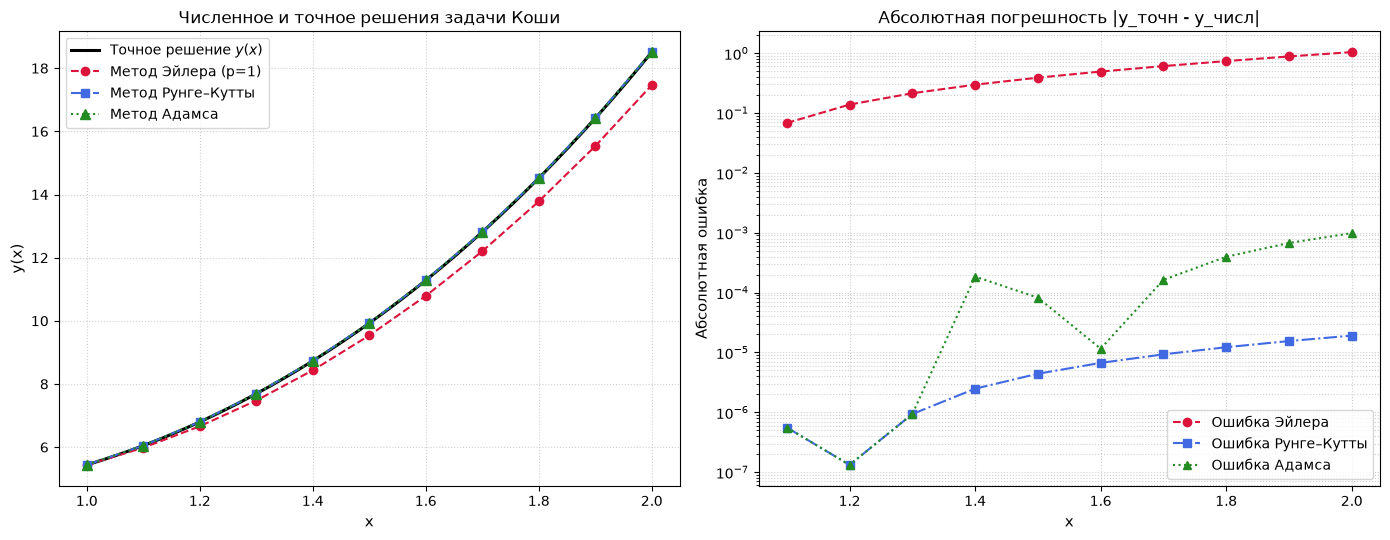

In [10]:
x_start = 1.0  
x_finish = 2.0  
step_h = 0.1  
    
u_init = [2.0 * np.e, 2.0 * np.e]

solve_koshi_task(odu_system, exact_solution, x_start, x_finish, u_init, step_h)

---
# **4.2. Метод стрельбы и конечно-разностный метод решения краевой задачи**

In [15]:
def exact_solution(x):
    return np.exp(x) * (x**2 + 1.0)


def odu_system(x, u):
    y, z = u[0], u[1]
    dy_dx = z

    if abs(x) < 1e-12:
        dz_dx = 3.0 * y
    else:
        dz_dx = ((2.0 * x + 1.0) * z - (x + 1.0) * y) / x

    return np.array([dy_dx, dz_dx], dtype=float)

def shooting_method(a, b, h, eta0=0.5, eta1=1.5, tol=1e-12, max_iter=20):
    def residual(eta):
        x, u = runge_kutta(odu_system, a, b, [eta, 1.0], h)
        phi = u[-1, 1] - 2.0 * u[-1, 0]
        return phi, x, u

    phi0, _, _ = residual(eta0)
    phi1, x, u = residual(eta1)

    if abs(phi1) < tol:
        return x, u[:, 0], eta1, 1

    eta_prev, phi_prev = eta0, phi0
    eta_curr, phi_curr = eta1, phi1

    for it in range(1, max_iter + 1):
        if abs(phi_curr - phi_prev) < 1e-15:
            break
        eta_next = eta_curr - (eta_curr - eta_prev) * phi_curr / (
            phi_curr - phi_prev
        )
        phi_next, x, u = residual(eta_next)

        if abs(phi_next) < tol:
            return x, u[:, 0], eta_next, it

        eta_prev, phi_prev = eta_curr, phi_curr
        eta_curr, phi_curr = eta_next, phi_next

    return x, u[:, 0], eta_curr, max_iter


def finite_difference_method(a, b, h):
    N = int(round((b - a) / h))
    x = np.linspace(a, b, N + 1)
    size = N + 1  

    lower = np.zeros(size, dtype=float)
    main = np.zeros(size, dtype=float)
    upper = np.zeros(size - 1, dtype=float)
    rhs = np.zeros(size, dtype=float)

    a_coef = np.zeros(size, dtype=float)
    b_coef = np.zeros(size, dtype=float)
    c_coef = np.zeros(size, dtype=float)

    for i in range(1, N):
        xi = x[i]
        a_coef[i] = xi + 0.5 * h * (2.0 * xi + 1.0)
        b_coef[i] = -2.0 * xi + (h**2) * (xi + 1.0)
        c_coef[i] = xi - 0.5 * h * (2.0 * xi + 1.0)

        lower[i] = a_coef[i]
        main[i] = b_coef[i]
        upper[i] = c_coef[i]
        rhs[i] = 0.0

    main[0] = -3.0 + a_coef[1] / c_coef[1]
    upper[0] = 4.0 + b_coef[1] / c_coef[1]
    rhs[0] = 2.0 * h

    lower[N] = -4.0 - b_coef[N - 1] / a_coef[N - 1]
    main[N] = (3.0 - 4.0 * h) - c_coef[N - 1] / a_coef[N - 1]
    rhs[N] = 0.0

    y = tridiag_solve(lower, main, upper, rhs)
    return x, y


def runge_romberg_error(y_h, y_h2, p):
    return np.abs(y_h2[::2] - y_h) / (2.0**p - 1.0)

def solve_bvp_task(a, b, h):
    x_h, y_shoot_h, eta_found, iters = shooting_method(a, b, h)
    _, y_fdm_h = finite_difference_method(a, b, h)

    h_half = h / 2.0
    _, y_shoot_h2, _, _ = shooting_method(a, b, h_half)
    _, y_fdm_h2 = finite_difference_method(a, b, h_half)

    y_ex = exact_solution(x_h)

    err_rr_shoot = runge_romberg_error(y_shoot_h, y_shoot_h2, p=4)
    err_rr_fdm = runge_romberg_error(y_fdm_h, y_fdm_h2, p=2)

    abs_err_shoot = np.abs(y_ex - y_shoot_h)
    abs_err_fdm = np.abs(y_ex - y_fdm_h)

    print("=" * 112)
    print(f"РЕШЕНИЕ КРАЕВОЙ ЗАДАЧИ НА ОТРЕЗКЕ [{a}; {b}] С ШАГОМ h = {h}")
    print(
        f"Метод стрельбы: подобран параметр y(0) = eta = {eta_found:.8f} (за {iters} итер. метода секущих)"
    )
    print("=" * 112)
    header = (
        f"{'i':^3} | {'x_i':^6} | {'Точное y(x)':^13} | "
        f"{'Стрельба (p=4)':^14} | {'КРМ (p=2)':^13} | "
        f"{'Абс.Стрельба':^13} | {'РР Стрельба':^12} | {'Абс.КРМ':^12} | {'РР КРМ':^12}"
    )
    print(header)
    print("-" * len(header))

    for i in range(len(x_h)):
        print(
            f"{i:^3} | {x_h[i]:^6.2f} | {y_ex[i]:^13.7f} | "
            f"{y_shoot_h[i]:^14.7f} | {y_fdm_h[i]:^13.7f} | "
            f"{abs_err_shoot[i]:^13.2e} | {err_rr_shoot[i]:^12.2e} | "
            f"{abs_err_fdm[i]:^12.2e} | {err_rr_fdm[i]:^12.2e}"
        )

    print("=" * 112)
    print("МАКСИМАЛЬНЫЕ ПОГРЕШНОСТИ НА ОТРЕЗКЕ [0; 1]:")
    print(
        f"  1. Метод стрельбы (p=4):             max|y_точн - y_h| = {np.max(abs_err_shoot):.3e}  |  max РР(h/2) = {np.max(err_rr_shoot):.3e}"
    )
    print(
        f"  2. Конечно-разностный метод (p=2):   max|y_точн - y_h| = {np.max(abs_err_fdm):.3e}  |  max РР(h/2) = {np.max(err_rr_fdm):.3e}"
    )
    print("=" * 112)

    # Построение графиков
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

    x_dense = np.linspace(a, b, 200)
    ax1.plot(
        x_dense,
        exact_solution(x_dense),
        "k-",
        linewidth=2.2,
        label="Точное решение $y(x) = e^x(x^2+1)$",
    )
    ax1.plot(
        x_h,
        y_shoot_h,
        "o--",
        color="royalblue",
        markersize=6,
        label="Метод стрельбы (РК4)",
    )
    ax1.plot(
        x_h,
        y_fdm_h,
        "s:",
        color="crimson",
        markersize=6,
        label="Конечно-разностный метод",
    )
    ax1.set_title("Численное и точное решения краевой задачи", fontsize=12)
    ax1.set_xlabel("x", fontsize=11)
    ax1.set_ylabel("y(x)", fontsize=11)
    ax1.grid(True, linestyle=":", alpha=0.6)
    ax1.legend(loc="best")

    ax2.semilogy(
        x_h,
        abs_err_shoot + 1e-16,
        "o--",
        color="royalblue",
        label="Ошибка метода стрельбы",
    )
    ax2.semilogy(
        x_h,
        abs_err_fdm + 1e-16,
        "s:",
        color="crimson",
        label="Ошибка конечно-разностного метода",
    )
    ax2.set_title(
        "Абсолютная погрешность |y_точн - y_числ| (лог. шкала)", fontsize=12
    )
    ax2.set_xlabel("x", fontsize=11)
    ax2.set_ylabel("Абсолютная ошибка", fontsize=11)
    ax2.grid(True, which="both", linestyle=":", alpha=0.6)
    ax2.legend(loc="best")

    plt.tight_layout()
    plt.show()

РЕШЕНИЕ КРАЕВОЙ ЗАДАЧИ НА ОТРЕЗКЕ [0.0; 1.0] С ШАГОМ h = 0.1
Метод стрельбы: подобран параметр y(0) = eta = 0.99901457 (за 1 итер. метода секущих)
 i  |  x_i   |  Точное y(x)  | Стрельба (p=4) |   КРМ (p=2)   | Абс.Стрельба  | РР Стрельба  |   Абс.КРМ    |    РР КРМ   
--------------------------------------------------------------------------------------------------------------------------
 0  |  0.00  |   1.0000000   |   0.9990146    |   1.0428966   |   9.85e-04    |   5.00e-05   |   4.29e-02   |   1.11e-02  
 1  |  0.10  |   1.1162226   |   1.1151346    |   1.1626160   |   1.09e-03    |   5.51e-05   |   4.64e-02   |   1.20e-02  
 2  |  0.20  |   1.2702589   |   1.2690165    |   1.3217742   |   1.24e-03    |   6.30e-05   |   5.15e-02   |   1.33e-02  
 3  |  0.30  |   1.4713461   |   1.4699023    |   1.5303237   |   1.44e-03    |   7.32e-05   |   5.90e-02   |   1.53e-02  
 4  |  0.40  |   1.7305166   |   1.7288134    |   1.8001172   |   1.70e-03    |   8.64e-05   |   6.96e-02   |   1.8

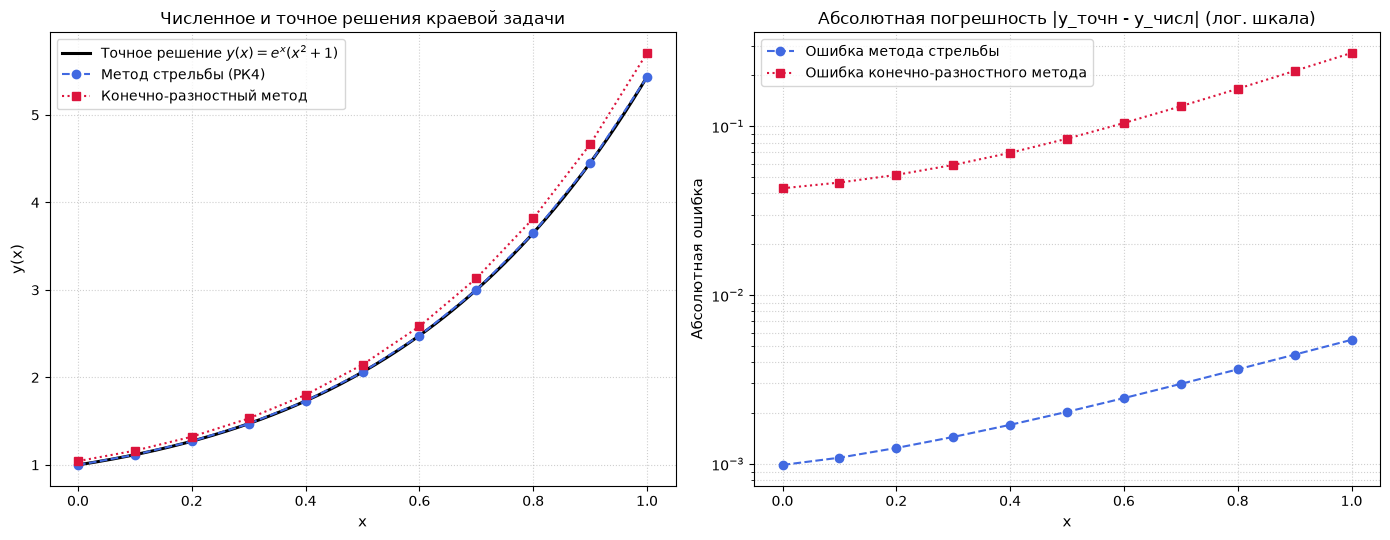

In [16]:
x_start = 0.0
x_end = 1.0
step_h = 0.1  

solve_bvp_task(x_start, x_end, step_h)